# traffic flow, trying some stuff

**Existing live baseline official composite: 0.72091** · previous full submission · higher is better

CPU state candidate: within-day interpolation + centered 5-point temporal median; missing estimator values fall back per state cell to the live profile/interpolation baseline. Queue and ODME methods are unchanged.

- 6,980,503 rows: state 6,735,795 · queue 174,000 · ODME 70,708. Physics is scored from state.
- Same-split July Task 1 check: live predictor 0.908535; temporal_median5 0.909307 (gain 0.000771) over 348,532 cells. The July result selected the candidate and is development evidence, not a composite score.
- Simple starter, not a top leaderboard method; queue and ODME use transparent baselines.

<div align="center">
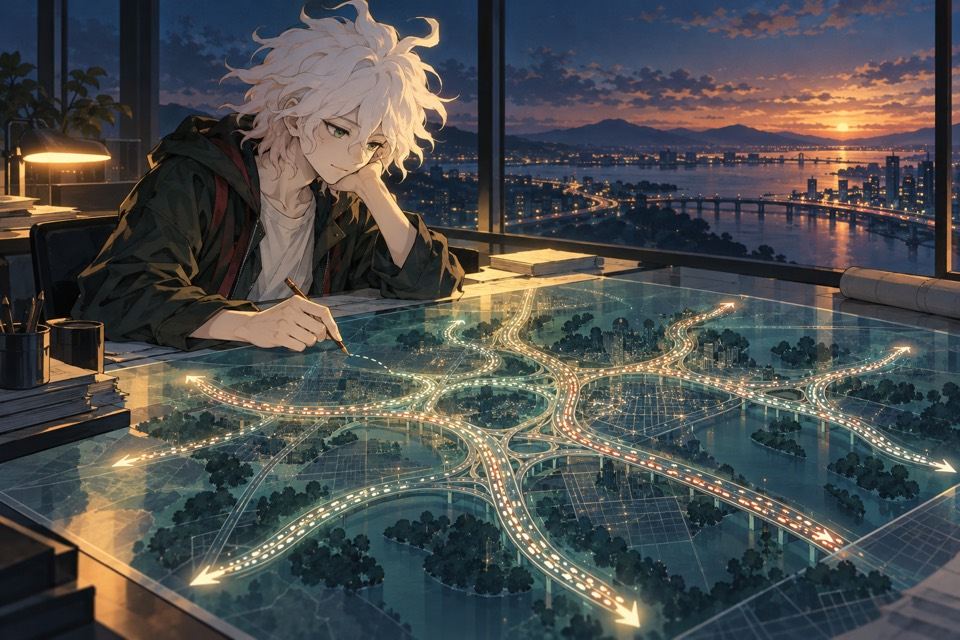
</div>

## data contract

The release's synthetic-data policy allows aggregate calibration and prohibits replaying or shifting historical rows. The state model uses station/link/weekday/time-slot medians as aggregate calibration, then interpolates only inside each supplied masked split. The train-month holdout keeps its matching unmasked labels out of the profile.

The official upload has three value columns to fill: `state`, `queue`, and `odme`. Physics is scored from `state`; there is no physics column. Task 1 uses equal regime means, a speed weight of 0.54, and a per-lane flow weight of 0.46. See the [official scoring spec](https://github.com/leigaadik/trafficflowbench/blob/main/docs/SCORING_SPEC.md), [release guide](https://github.com/jacky850/trafficflowbench-public/blob/main/docs/DATA.md), [submission schemas](https://github.com/jacky850/trafficflowbench-public/blob/main/docs/SUBMISSION_SCHEMAS.md), and [official baselines](https://github.com/jacky850/trafficflowbench-public/blob/main/docs/BASELINES.md).

One local CatBoost check reached 0.9320 on the same D12_I405_N holdout, about 0.0010 above interpolation; only one CatBoost configuration completed. The final file uses the simpler interpolation/profile method so the measured result is easy to reproduce across all panels.

Credits: competition organizers and the public TrafficFlowBench data/scoring documentation. No public notebook code reused.

In [ ]:
import os
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
os.environ["NUMEXPR_NUM_THREADS"] = "2"

from pathlib import Path
import json, time, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from threadpoolctl import threadpool_limits
get_ipython().run_line_magic("matplotlib", "inline")

PALETTE = {
    "navy": "#15324B", "teal": "#20A39E", "coral": "#F26B5B",
    "amber": "#F2B134", "mint": "#9ADBC5", "paper": "#F6F7F2",
}
plt.rcParams.update({"figure.facecolor": PALETTE["paper"], "axes.facecolor": PALETTE["paper"],
                     "axes.edgecolor": PALETTE["navy"], "axes.labelcolor": PALETTE["navy"],
                     "text.color": PALETTE["navy"], "xtick.color": PALETTE["navy"],
                     "ytick.color": PALETTE["navy"], "font.size": 10})
THREAD_LIMIT = threadpool_limits(limits=2)
RUN_STARTED = time.monotonic()

def is_release_root(path):
    return (path / "sample_submission.csv").is_file() and (path / "corridors").is_dir()

def discover_release():
    candidates = []
    env_root = os.environ.get("TFB_DATA_ROOT")
    if env_root:
        candidates.append(Path(env_root).expanduser())
    competition_root = Path("/kaggle/input/competitions/2026-ieee-big-data-traffic-flow-bench")
    candidates += [competition_root, competition_root / "kaggle_public", Path("/kaggle/input"), Path.cwd(), Path.cwd() / "_shared" / "data"]
    for base in candidates:
        if not base.exists():
            continue
        if is_release_root(base):
            return base.resolve()
        if is_release_root(base / "kaggle_public"):
            return (base / "kaggle_public").resolve()
        try:
            for child in base.iterdir():
                if is_release_root(child):
                    return child.resolve()
                if is_release_root(child / "kaggle_public"):
                    return (child / "kaggle_public").resolve()
        except (PermissionError, NotADirectoryError):
            pass
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        archives = list(input_root.glob("*.zip"))
        for child in input_root.iterdir():
            if child.is_dir():
                archives.extend(child.glob("*.zip"))
        for archive in sorted(archives):
            with zipfile.ZipFile(archive) as bundle:
                names = bundle.namelist()
                if "kaggle_public/sample_submission.csv" not in names:
                    continue
                destination = Path("/kaggle/working/tfb-release")
                release = destination / "kaggle_public"
                if is_release_root(release):
                    return release
                if destination.exists():
                    raise FileExistsError(f"Incomplete extraction already exists at {destination}; inspect it before retrying.")
                members = [name for name in names if name.startswith("kaggle_public/")]
                bundle.extractall(destination, members=members)
                return release
    raise FileNotFoundError("Could not find the release root with sample_submission.csv and corridors/.")

ROOT = discover_release()
CONTRACT = json.loads((ROOT / "config" / "competition_contract.json").read_text())
PANELS = [p["corridor_id"] for p in json.loads((ROOT / "config" / "corridors.json").read_text())["panels"]]
STATE_KEYS = ["panel", "timestamp", "station_id", "link_id", "mask_regime"]
TRUTH_KEYS = ["panel", "timestamp", "station_id", "link_id"]
print(f"release: {ROOT} | {len(PANELS)} panels | two-thread cap")

## task 1 · a centered temporal-median state estimate

The live notebook predictor scored 0.908535 on the fixed July 2030 Task 1 sample. The within-day `temporal_median5` estimator scored 0.909307 on the identical 348,532 target keys under the organizer evaluator. It interpolates only the released masked day, smooths each detector's speed and per-lane flow over five 5-minute steps, and uses the live predictor per value when the candidate is missing or non-finite. The July sample was used to select this candidate, so this is development evidence, not an independent test or composite score.

Flow is estimated per lane and multiplied back by detector lanes for the upload. Regime scoring and family/direction macro-averaging follow the official Task 1 evaluator.

In [ ]:
FALLBACK_ROWS = 0
COUNT_FALLBACKS = False

def empty_frame(columns):
    text_columns = {"timestamp", "station_id", "link_id", "mask_regime"}
    return pd.DataFrame({name: pd.Series(dtype="string" if name in text_columns else "float64")
                         for name in columns})

def read_month(directory, month, columns):
    token = month.replace("-", "_")
    files = sorted(p for p in Path(directory).rglob("*.parquet") if token in p.name)
    frames = []
    for path in files:
        try:
            frames.append(pd.read_parquet(path, columns=columns))
        except Exception as error:
            print(f"WARNING: skipped unreadable month file {path.name}: {error}")
    if not frames:
        print(f"WARNING: no usable {month} files under {directory}; later steps use released physical fallbacks")
        return empty_frame(columns)
    return pd.concat(frames, ignore_index=True)

def read_all(directory, columns, exclude_month=None):
    files = sorted(p for p in Path(directory).rglob("*.parquet"))
    if exclude_month:
        token = exclude_month.replace("-", "_")
        files = [p for p in files if token not in p.name]
    frames = []
    for path in files:
        try:
            frames.append(pd.read_parquet(path, columns=columns))
        except Exception as error:
            print(f"WARNING: skipped unreadable history file {path.name}: {error}")
    if not frames:
        print(f"WARNING: no usable history under {directory}; later steps use released physical fallbacks")
        return empty_frame(columns)
    return pd.concat(frames, ignore_index=True)

def state_template(panel, split):
    path = ROOT / "task1" / panel / split / "sample_submission_state.csv"
    if path.is_file():
        try:
            chunks = []
            for part in pd.read_csv(path, usecols=STATE_KEYS, chunksize=500_000,
                                    dtype={k: "string" for k in STATE_KEYS}):
                chunks.append(part)
            if chunks:
                return pd.concat(chunks, ignore_index=True).drop_duplicates(STATE_KEYS)
        except Exception as error:
            print(f"WARNING: state template read failed for {panel}/{split}: {error}")
    print(f"WARNING: using submission-key rows for state template {panel}/{split}")
    try:
        usecols = list(dict.fromkeys(["task", "split"] + STATE_KEYS))
        key = pd.read_csv(ROOT / "submission_key.csv", usecols=usecols,
                          dtype={k: "string" for k in usecols})
        target = key[key.task.eq("state") & key.panel.eq(panel) & key.split.eq(split)]
        return target[STATE_KEYS].drop_duplicates(STATE_KEYS).reset_index(drop=True)
    except Exception as error:
        print(f"WARNING: no state template fallback for {panel}/{split}: {error}")
        return empty_frame(STATE_KEYS)

def build_profile(panel, exclude_month=None):
    directory = ROOT / "corridors" / panel / "train" / "mainline_states"
    hist = read_all(directory, ["timestamp", "station_id", "link_id", "speed_kmh", "flow_vph", "is_score_eligible"], exclude_month)
    hist = hist[hist.is_score_eligible.eq(1) & hist.speed_kmh.notna() & hist.flow_vph.notna()].copy()
    dt = pd.to_datetime(hist.timestamp, utc=True)
    hist["dow"] = dt.dt.dayofweek.astype("int8")
    hist["slot"] = ((dt.dt.hour * 60 + dt.dt.minute) // 15).astype("int16")
    profile = hist.groupby(["station_id", "link_id", "dow", "slot"], observed=True).agg(
        profile_speed=("speed_kmh", "median"), profile_flow=("flow_vph", "median")).reset_index()
    fallback = hist.groupby(["station_id", "link_id"], observed=True).agg(
        fallback_speed=("speed_kmh", "median"), fallback_flow=("flow_vph", "median")).reset_index()
    return profile, fallback

def temporal_median5_estimates(masked, panel):
    """Return per-row within-day median5 estimates; failures remain NaN for baseline fallback."""
    speed_estimate = np.full(len(masked), np.nan, dtype=float)
    flow_estimate = np.full(len(masked), np.nan, dtype=float)
    if masked.empty:
        return speed_estimate, flow_estimate
    links_path = ROOT / "corridors" / panel / "network" / "links.csv"
    try:
        links = pd.read_csv(links_path, usecols=["link_id", "lanes"])
        links = links.drop_duplicates("link_id", keep="first")
        lane_map = dict(zip(links.link_id.astype(str), pd.to_numeric(links.lanes, errors="coerce")))
    except Exception as error:
        print(f"WARNING: median5 lane metadata unavailable for {panel}; using live baseline per cell: {error}")
        return speed_estimate, flow_estimate

    work = masked.copy()
    work["_row_position"] = np.arange(len(work), dtype=np.int64)
    work["_lane_count"] = work.link_id.astype(str).map(lane_map)
    work["_lane_count"] = pd.to_numeric(work["_lane_count"], errors="coerce").where(
        pd.to_numeric(work["_lane_count"], errors="coerce") > 0
    )
    work["_speed_input"] = pd.to_numeric(work.speed_kmh, errors="coerce")
    work["_flow_lane_input"] = pd.to_numeric(work.flow_vph, errors="coerce") / work["_lane_count"]
    work["_day_key"] = work.dt.dt.strftime("%Y-%m-%d")

    for day_key, rows in work.groupby("_day_key", sort=True):
        positions = rows["_row_position"].to_numpy(dtype=np.int64)
        try:
            candidates = {}
            for input_column, output_name in (
                ("_speed_input", "speed"),
                ("_flow_lane_input", "flow_lane"),
            ):
                matrix = rows.pivot(index="timestamp", columns="link_id", values=input_column)
                observed = matrix.to_numpy(dtype=float)
                temporal = matrix.interpolate(axis=0, method="linear", limit_direction="both")
                link_medians = matrix.median(axis=0)
                for column in temporal.columns:
                    temporal[column] = temporal[column].fillna(link_medians[column])
                global_median = float(np.nanmedian(observed)) if np.isfinite(observed).any() else 0.0
                temporal = temporal.fillna(global_median)
                smoothed = temporal.rolling(window=5, center=True, min_periods=1).median()
                time_to_row = {value: index for index, value in enumerate(matrix.index)}
                link_to_column = {value: index for index, value in enumerate(matrix.columns)}
                time_positions = rows.timestamp.map(time_to_row).to_numpy(dtype=np.int64)
                link_positions = rows.link_id.map(link_to_column).to_numpy(dtype=np.int64)
                candidates[output_name] = smoothed.to_numpy(dtype=float)[time_positions, link_positions]
            speed_estimate[positions] = candidates["speed"]
            flow_estimate[positions] = candidates["flow_lane"] * rows["_lane_count"].to_numpy(dtype=float)
        except Exception as error:
            print(f"WARNING: median5 estimator failed for {panel} {day_key}; using live baseline per cell: {error}")
    return speed_estimate, flow_estimate


def prepare_state_rows(panel, split, target, profile, fallback, month=None):
    global FALLBACK_ROWS
    root = ROOT / "corridors" / panel / split
    masked_dir = root / "mainline_states_masked"
    columns = ["timestamp", "station_id", "link_id", "speed_kmh", "flow_vph", "mask_regime"]
    masked = read_month(masked_dir, month, columns) if month else read_all(masked_dir, columns)
    masked["panel"] = panel
    if masked.duplicated(STATE_KEYS).any():
        print(f"WARNING: duplicate masked keys in {panel}/{split}; keeping the first released row")
        masked = masked.drop_duplicates(STATE_KEYS, keep="first")
    masked["dt"] = pd.to_datetime(masked.timestamp, utc=True)
    masked = masked.sort_values(["station_id", "link_id", "dt"], kind="mergesort").reset_index(drop=True)
    try:
        median5_speed, median5_flow = temporal_median5_estimates(masked, panel)
    except Exception as error:
        print(f"WARNING: median5 setup failed for {panel}/{split}; using live baseline per cell: {error}")
        median5_speed = np.full(len(masked), np.nan, dtype=float)
        median5_flow = np.full(len(masked), np.nan, dtype=float)
    masked["median5_speed"] = median5_speed
    masked["median5_flow_vph"] = median5_flow
    groups = [masked.station_id, masked.link_id]
    for source, name in (("speed_kmh", "speed"), ("flow_vph", "flow")):
        masked[f"linear_{name}"] = masked.groupby(["station_id", "link_id"], sort=False)[source].transform(
            lambda s: s.interpolate(method="linear", limit_direction="both"))
    observed_time = masked.dt.where(masked.speed_kmh.notna())
    left = observed_time.groupby(groups, sort=False).ffill()
    right = observed_time.groupby(groups, sort=False).bfill()
    masked["gap_steps"] = (right - left).dt.total_seconds() / 300.0
    query = target[STATE_KEYS].merge(masked[STATE_KEYS + ["dt", "linear_speed", "linear_flow", "gap_steps", "median5_speed", "median5_flow_vph"]],
                                      on=STATE_KEYS, how="left", validate="one_to_one")
    missing_mask = query.dt.isna()
    if len(query) != len(target) or missing_mask.any():
        print(f"WARNING: masked-key coverage changed for {panel}/{split}; using released profiles and physical values")
        query["dt"] = query.dt.fillna(pd.to_datetime(query["timestamp"], utc=True))
    query["dow"] = query.dt.dt.dayofweek.fillna(0).astype("int16")
    query["slot"] = ((query.dt.dt.hour.fillna(0) * 60 + query.dt.dt.minute.fillna(0)) // 15).astype("int16")
    profile = profile.drop_duplicates(["station_id", "link_id", "dow", "slot"], keep="first")
    fallback = fallback.drop_duplicates(["station_id", "link_id"], keep="first")
    query = query.merge(profile, on=["station_id", "link_id", "dow", "slot"], how="left")
    query = query.merge(fallback, on=["station_id", "link_id"], how="left")
    links_path = ROOT / "corridors" / panel / "network" / "links.csv"
    try:
        links = pd.read_csv(links_path, usecols=["link_id", "lanes", "free_speed_kmh", "capacity_vph"])
        links = links.drop_duplicates("link_id", keep="first")
    except Exception as error:
        print(f"WARNING: link metadata unavailable for {panel}; using a simple physical fallback: {error}")
        link_ids = target["link_id"].dropna().astype("string").drop_duplicates()
        links = pd.DataFrame({"link_id": link_ids, "lanes": 1, "free_speed_kmh": 60.0, "capacity_vph": 1000.0})
    query = query.merge(links, on="link_id", how="left")
    missing_physics = query[["lanes", "profile_speed", "profile_flow"]].isna().any(axis=1)
    if missing_physics.any():
        print(f"WARNING: {int(missing_physics.sum())} state rows use free-speed/capacity fallback in {panel}/{split}")
        if COUNT_FALLBACKS:
            FALLBACK_ROWS += int(missing_physics.sum())
    query["lanes"] = query["lanes"].fillna(1).clip(lower=1)
    query["profile_speed"] = query.profile_speed.fillna(query.free_speed_kmh).fillna(60.0)
    query["profile_flow"] = query.profile_flow.fillna(query.fallback_flow).fillna(query.capacity_vph * 0.5).fillna(1000.0)
    return query

def score_state(rows, pred_speed, pred_flow):
    detail = {}
    for regime, group in rows.groupby("mask_regime", sort=True):
        ix = group.index.to_numpy()
        rs = float(np.sqrt(np.mean((pred_speed[ix] - group.true_speed.to_numpy(float)) ** 2)))
        rq = float(np.sqrt(np.mean(((pred_flow[ix] - group.true_flow.to_numpy(float)) / group.lanes.to_numpy(float)) ** 2)))
        ss, sf = max(0.0, 1.0 - rs / 25.0), max(0.0, 1.0 - rq / 600.0)
        detail[str(regime)] = {"n": int(len(group)), "rmse_speed_kmh": rs,
                               "rmse_flow_vph_per_lane": rq, "S_speed": ss,
                               "S_flow": sf, "S_state": 0.54 * ss + 0.46 * sf}
    return float(np.mean([v["S_state"] for v in detail.values()])), detail

HOLDOUT_PANEL, HOLDOUT_MONTH = "D12_I405_N", "2031-02"
train_template = state_template(HOLDOUT_PANEL, "train")
target_holdout = train_template[train_template.timestamp.str.startswith(HOLDOUT_MONTH)].copy()
profile_holdout, fallback_holdout = build_profile(HOLDOUT_PANEL, exclude_month=HOLDOUT_MONTH)
query = prepare_state_rows(HOLDOUT_PANEL, "train", target_holdout, profile_holdout, fallback_holdout, month=HOLDOUT_MONTH)
truth = read_month(ROOT / "corridors" / HOLDOUT_PANEL / "train" / "mainline_states", HOLDOUT_MONTH,
                   ["timestamp", "station_id", "link_id", "speed_kmh", "flow_vph"])
truth["panel"] = HOLDOUT_PANEL
query = query.merge(truth.rename(columns={"speed_kmh": "true_speed", "flow_vph": "true_flow"}),
                    on=TRUTH_KEYS, how="left", validate="one_to_one")
holdout_missing = query[["true_speed", "true_flow"]].isna().any(axis=1)
if len(query) != len(target_holdout) or holdout_missing.any():
    print(f"WARNING: February holdout keys/labels changed; skipping rows without released truth ({int(holdout_missing.sum())})")
    query = query.loc[~holdout_missing].copy()
PROFILE_CACHE = {HOLDOUT_PANEL: (profile_holdout, fallback_holdout)}

metric_fallback = 0.9114814084663877
if query.empty:
    print("WARNING: no February holdout rows remain; using the carried-forward Task 1 reference for the in-run check")
    best_score, best_detail = metric_fallback, {}
    best_speed = np.array([], dtype=float)
    best_flow = np.array([], dtype=float)
    query["pred_speed"] = best_speed
    query["pred_flow"] = best_flow
    grid = [{"max_gap": 48, "alpha": 1.0, "score": metric_fallback, "detail": {},
             "speed": best_speed, "flow": best_flow}]
else:
    linear_speed = query.linear_speed.to_numpy(float)
    linear_flow = query.linear_flow.to_numpy(float)
    profile_speed = query.profile_speed.to_numpy(float)
    profile_flow = query.profile_flow.to_numpy(float)
    gap = query.gap_steps
    grid = []
    for max_gap in (3, 6, 12, 24, 48):
        short = gap.le(max_gap + 1).fillna(False).to_numpy()
        interp_speed = np.where(np.isfinite(linear_speed), linear_speed, profile_speed)
        interp_flow = np.where(np.isfinite(linear_flow), linear_flow, profile_flow)
        interp_speed = np.where(short, interp_speed, profile_speed)
        interp_flow = np.where(short, interp_flow, profile_flow)
        for alpha in (0.0, 0.25, 0.5, 0.75, 1.0):
            ps = np.clip((1-alpha) * profile_speed + alpha * interp_speed, 0, 150)
            pf = np.maximum((1-alpha) * profile_flow + alpha * interp_flow, 0)
            value, detail = score_state(query, ps, pf)
            grid.append({"max_gap": max_gap, "alpha": alpha, "score": value, "detail": detail,
                         "speed": ps, "flow": pf})
    best_grid = max(grid, key=lambda row: row["score"] if np.isfinite(row["score"]) else -1.0)
    best_score, best_detail = best_grid["score"], best_grid["detail"]
    if not np.isfinite(best_score):
        print("WARNING: holdout score is non-finite; retaining the carried-forward Task 1 reference")
        best_score = metric_fallback
    best_speed, best_flow = best_grid["speed"], best_grid["flow"]
    query["pred_speed"], query["pred_flow"] = best_speed, best_flow
PROFILE_CACHE = {HOLDOUT_PANEL: (profile_holdout, fallback_holdout)}
COUNT_FALLBACKS = True
print(json.dumps({"panel": HOLDOUT_PANEL, "holdout_month": HOLDOUT_MONTH,
                  "rows": len(query), "best_score": best_score,
                  "score_type": "Task 1 development holdout, not composite leaderboard score",
                  "by_regime": best_detail}, indent=2))

VERIFIED_TASK1_JULY_SCORE = 0.909306629534056


In [ ]:
# Figure 1: exact-score candidate surface.
score_grid = pd.DataFrame([{"max_gap": x["max_gap"], "alpha": x["alpha"], "score": x["score"]} for x in grid])
heat = score_grid.pivot(index="max_gap", columns="alpha", values="score").sort_index()
cmap = LinearSegmentedColormap.from_list("traffic", [PALETTE["navy"], PALETTE["teal"], PALETTE["amber"], PALETTE["coral"]])
fig, ax = plt.subplots(figsize=(8.4, 4.4))
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap=cmap, vmin=heat.to_numpy().min(), vmax=heat.to_numpy().max())
ax.set_xticks(range(len(heat.columns)), [f"{x:.2f}" for x in heat.columns])
ax.set_yticks(range(len(heat.index)), [str(x) for x in heat.index])
ax.set_xlabel("linear interpolation weight, α"); ax.set_ylabel("maximum gap (5-minute steps)")
ax.set_title("Task 1 · exact February holdout score")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.iloc[i,j]:.3f}", ha="center", va="center", color="white", fontsize=9)
fig.colorbar(im, ax=ax, label="macro S_state"); fig.tight_layout(); plt.show()

# Figure 2: cross-panel scores for the pooled setting selected on this same holdout month.
PANEL_HOLDOUT_SCORES = {
    "D7_I10_E": 0.9135262364500324, "D7_I10_W": 0.9308073289541481,
    "D7_I210_E": 0.9201620661356890, "D7_I210_W": 0.8985072640790120,
    "D7_I405_N": 0.8863730937264354, "D7_I405_S": 0.8953235951068601,
    "D12_I5_N": 0.9132522696381579, "D12_I5_S": 0.9130383167307653,
    "D12_I405_N": 0.9309992404877990, "D12_I405_S": 0.9128246733549785,
}
PANEL_FAMILIES = {
    "D7_I10_E": "D7 I-10", "D7_I10_W": "D7 I-10",
    "D7_I210_E": "D7 I-210", "D7_I210_W": "D7 I-210",
    "D7_I405_N": "D7 I-405", "D7_I405_S": "D7 I-405",
    "D12_I5_N": "D12 I-5", "D12_I5_S": "D12 I-5",
    "D12_I405_N": "D12 I-405", "D12_I405_S": "D12 I-405",
}
family_colors = {"D7 I-10": PALETTE["teal"], "D7 I-210": PALETTE["amber"],
                 "D7 I-405": PALETTE["coral"], "D12 I-5": PALETTE["mint"],
                 "D12 I-405": PALETTE["navy"]}
panel_order = [p for p in PANELS if p in PANEL_HOLDOUT_SCORES]
panel_values = [PANEL_HOLDOUT_SCORES[p] for p in panel_order]
fig, ax = plt.subplots(figsize=(10.8, 4.7))
ax.bar(np.arange(len(panel_order)), panel_values,
       color=[family_colors[PANEL_FAMILIES[p]] for p in panel_order], width=.76)
ax.axhline(.9114814084663877, color=PALETTE["navy"], lw=1.5, ls="--", label="equal-family mean · 0.9115")
ax.set_xticks(np.arange(len(panel_order)), [p.replace("D7_", "").replace("D12_", "") for p in panel_order], rotation=45, ha="right")
ax.set_ylim(.87, .94); ax.set_ylabel("Task 1 S_state")
ax.set_title("ten-panel February holdout · pooled 48-step setting")
ax.legend(frameon=False); fig.tight_layout(); plt.show()

# Figure 3: score components by masking regime for the selected candidate.
regimes = list(best_detail)
x = np.arange(len(regimes)); width = 0.34
fig, ax = plt.subplots(figsize=(7.8, 4.2))
ax.bar(x-width/2, [best_detail[r]["S_speed"] for r in regimes], width, color=PALETTE["teal"], label="speed")
ax.bar(x+width/2, [best_detail[r]["S_flow"] for r in regimes], width, color=PALETTE["coral"], label="flow per lane")
ax.set_ylim(0.85, 1.0); ax.set_xticks(x, regimes); ax.set_ylabel("normalized score")
ax.set_title("where the holdout score comes from"); ax.legend(frameon=False, ncol=2)
fig.tight_layout(); plt.show()

In [ ]:
# Figure 4: measured versus predicted values. The point sample is only for display.
rng = np.random.default_rng(19)
sample_ix = rng.choice(len(query), size=min(9000, len(query)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.7))
colors = {"R1": PALETTE["teal"], "R2": PALETTE["amber"], "R3": PALETTE["coral"]}
for regime, color in colors.items():
    ix = query.index[query.mask_regime.eq(regime)].to_numpy()
    ix = np.intersect1d(ix, sample_ix, assume_unique=False)
    axes[0].scatter(query.loc[ix, "true_speed"], query.loc[ix, "pred_speed"], s=7, alpha=.35, c=color, label=regime)
    axes[1].scatter(query.loc[ix, "true_flow"] / query.loc[ix, "lanes"],
                    query.loc[ix, "pred_flow"] / query.loc[ix, "lanes"], s=7, alpha=.35, c=color, label=regime)
for ax, label in zip(axes, ["speed (km/h)", "flow (vph per lane)"]):
    limits = ax.get_xlim(); limits = (min(limits[0], ax.get_ylim()[0]), max(limits[1], ax.get_ylim()[1]))
    ax.plot(limits, limits, color=PALETTE["navy"], lw=1.2, ls="--"); ax.set_xlim(limits); ax.set_ylim(limits)
    ax.set_xlabel(f"measured {label}"); ax.set_ylabel(f"predicted {label}")
axes[0].set_title("speed"); axes[1].set_title("flow per lane")
axes[1].legend(frameon=False, title="mask")
fig.suptitle("February holdout · random sample for readability"); fig.tight_layout(); plt.show()

# Figure 5: residual error by observed interpolation gap.
gaps = query.gap_steps.fillna(np.inf)
gap_bins = pd.cut(gaps, bins=[-0.1, 2, 4, 8, 16, 32, np.inf],
                  labels=["≤2", "3–4", "5–8", "9–16", "17–32", ">32 / edge"])
diagnostic = query.assign(gap_bin=gap_bins,
    speed_error=(query.pred_speed-query.true_speed),
    flow_error=(query.pred_flow-query.true_flow)/query.lanes)
summary = diagnostic.groupby("gap_bin", observed=False).agg(
    speed_rmse=("speed_error", lambda s: float(np.sqrt(np.mean(s**2)))),
    flow_rmse=("flow_error", lambda s: float(np.sqrt(np.mean(s**2)))), n=("gap_bin", "size"))
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.plot(summary.index.astype(str), summary.speed_rmse, marker="o", lw=2.2, color=PALETTE["teal"], label="speed RMSE")
ax.set_ylabel("speed RMSE (km/h)"); ax.set_xlabel("gap length in 5-minute steps")
ax2 = ax.twinx(); ax2.plot(summary.index.astype(str), summary.flow_rmse, marker="s", lw=2.2, color=PALETTE["coral"], label="flow RMSE")
ax2.set_ylabel("flow RMSE (vph per lane)"); ax.set_title("error versus gap length")
ax.grid(axis="y", alpha=.2); fig.tight_layout(); plt.show()
print("gap-bin rows:", summary.n.to_dict())

## task 1 · fill both hidden months

For each panel and masked split, the state candidate uses only observed values in that same released day. It linearly fills each detector series, then takes a centered five-step median. If the estimator cannot produce a finite speed or flow value for a target, that value uses the original weekday/15-minute profile and short-gap interpolation baseline. The validation and private labels are never opened. This method changes Task 1 state predictions; queue persistence and ODME path-flow fitting remain as documented.

In [ ]:
state_parts = []

def physical_state_fallback(panel, split):
    target = state_template(panel, split)
    if target.empty:
        return pd.DataFrame(columns=STATE_KEYS + ["speed_kmh", "flow_vph"])
    links_path = ROOT / "corridors" / panel / "network" / "links.csv"
    try:
        links = pd.read_csv(links_path, usecols=["link_id", "free_speed_kmh", "capacity_vph"])
        links = links.drop_duplicates("link_id", keep="first")
    except Exception as error:
        print(f"WARNING: physical network fallback unavailable for {panel}: {error}")
        links = pd.DataFrame({"link_id": target.link_id.dropna().astype("string").drop_duplicates(),
                              "free_speed_kmh": 60.0, "capacity_vph": 1000.0})
    pred = target.merge(links, on="link_id", how="left")
    pred["speed_kmh"] = pd.to_numeric(pred.free_speed_kmh, errors="coerce").fillna(60.0).clip(0, 150)
    pred["flow_vph"] = pd.to_numeric(pred.capacity_vph, errors="coerce").fillna(2000.0).mul(0.5).clip(lower=0)
    return pred[STATE_KEYS + ["speed_kmh", "flow_vph"]]

for panel in PANELS:
    try:
        prof, fb = PROFILE_CACHE.get(panel, (None, None))
        if prof is None or panel == HOLDOUT_PANEL:
            prof, fb = build_profile(panel)
            PROFILE_CACHE[panel] = (prof, fb)
    except Exception as error:
        print(f"WARNING: state profile failed for {panel}; using physical fallback: {error}")
        prof = pd.DataFrame(columns=["station_id", "link_id", "dow", "slot", "profile_speed", "profile_flow"])
        fb = pd.DataFrame(columns=["station_id", "link_id", "fallback_speed", "fallback_flow"])
    for split in ("validation", "private"):
        try:
            target = state_template(panel, split)
            q = prepare_state_rows(panel, split, target, prof, fb)
            baseline_s = np.where(
                np.isfinite(q.linear_speed.to_numpy(float)),
                q.linear_speed.to_numpy(float), q.profile_speed.to_numpy(float)
            )
            baseline_f = np.where(
                np.isfinite(q.linear_flow.to_numpy(float)),
                q.linear_flow.to_numpy(float), q.profile_flow.to_numpy(float)
            )
            use_baseline_profile = q.gap_steps.le(49).fillna(False).to_numpy()
            baseline_s = np.clip(np.where(use_baseline_profile, baseline_s, q.profile_speed.to_numpy(float)), 0, 150)
            baseline_f = np.maximum(np.where(use_baseline_profile, baseline_f, q.profile_flow.to_numpy(float)), 0)

            candidate_s = pd.to_numeric(q.median5_speed, errors="coerce").to_numpy(dtype=float)
            candidate_f = pd.to_numeric(q.median5_flow_vph, errors="coerce").to_numpy(dtype=float)
            valid_s = np.isfinite(candidate_s)
            valid_f = np.isfinite(candidate_f)
            fallback_rows = ~(valid_s & valid_f)
            pred_s = np.where(valid_s, candidate_s, baseline_s)
            pred_f = np.where(valid_f, candidate_f, baseline_f)
            FALLBACK_ROWS += int(fallback_rows.sum())
            if fallback_rows.any():
                print(f"WARNING: median5 used the live baseline for {int(fallback_rows.sum())} state rows in {panel}/{split}")
            q["speed_kmh"], q["flow_vph"] = pred_s, pred_f
            part = q[STATE_KEYS + ["speed_kmh", "flow_vph"]]
        except Exception as error:
            print(f"WARNING: state pipeline failed for {panel}/{split}; using physical fallback: {error}")
            try:
                part = physical_state_fallback(panel, split)
            except Exception as fallback_error:
                print(f"WARNING: state fallback also changed for {panel}/{split}; using safe values: {fallback_error}")
                target = state_template(panel, split)
                part = target.copy()
                part["speed_kmh"], part["flow_vph"] = 60.0, 1000.0
                part = part[STATE_KEYS + ["speed_kmh", "flow_vph"]]
            FALLBACK_ROWS += len(part)
        state_parts.append(part)
    print(f"state predictions ready: {panel}")
state_predictions = pd.concat(state_parts, ignore_index=True) if state_parts else pd.DataFrame(columns=STATE_KEYS + ["speed_kmh", "flow_vph"])
if state_predictions.duplicated(STATE_KEYS).any():
    print("WARNING: duplicate state predictions; keeping the first natural-key row")
    state_predictions = state_predictions.drop_duplicates(STATE_KEYS, keep="first")
print(f"state prediction rows: {len(state_predictions):,}")


## task 2 · carry the observed queue state forward

The queue baseline labels a link queued when its latest score-eligible history speed is at or below 60% of that link's free speed. It persists that binary state through the six-step forecast horizon. Links without an eligible history reading default to no queue and are counted below. No hidden horizon truth is opened.


In [ ]:
def queue_template(panel, split):
    path = ROOT / "task2" / panel / split / "sample_submission_queue.csv"
    columns = ["window_id", "timestamp", "link_id"]
    dtypes = {name: "string" for name in columns}
    if path.is_file():
        try:
            return pd.read_csv(path, dtype=dtypes)[columns].drop_duplicates(columns)
        except Exception as error:
            print(f"WARNING: queue template changed for {panel}/{split}: {error}")
    print(f"WARNING: using submission-key rows for queue template {panel}/{split}")
    try:
        key = pd.read_csv(ROOT / "submission_key.csv",
                          usecols=["task", "split", "panel"] + columns,
                          dtype={name: "string" for name in ["task", "split", "panel"] + columns})
        return key[key.task.eq("queue") & key.panel.eq(panel) & key.split.eq(split)][columns].drop_duplicates(columns)
    except Exception as error:
        print(f"WARNING: queue template fallback unavailable for {panel}/{split}: {error}")
        return pd.DataFrame(columns=columns)

queue_parts = []
missing_cells = 0
QUEUE_KEYS = ["window_id", "timestamp", "link_id"]
for panel in PANELS:
    for split in ("validation", "private"):
        target = queue_template(panel, split)
        if target.empty:
            continue
        try:
            hist = pd.read_parquet(ROOT / "task2" / panel / split / "window_history.parquet")
            links = pd.read_csv(ROOT / "corridors" / panel / "network" / "links.csv",
                                usecols=["link_id", "free_speed_kmh"]).drop_duplicates("link_id", keep="first")
            hist["window_id"] = hist.window_id.astype("string")
            hist["link_id"] = hist.link_id.astype("string")
            links["link_id"] = links.link_id.astype("string")
            hist = hist.merge(links, on="link_id", how="left")
            hist = hist[hist.is_score_eligible.eq(1) & hist.speed_kmh.notna() & hist.free_speed_kmh.notna()].copy()
            hist["queue_state"] = (hist.speed_kmh <= .60 * hist.free_speed_kmh).astype("int8")
            hist["dt"] = pd.to_datetime(hist.timestamp, utc=True)
            last = (hist.sort_values("dt").groupby(["window_id", "link_id"], sort=False).tail(1)
                    [["window_id", "link_id", "queue_state"]])
            pred = target.merge(last, on=["window_id", "link_id"], how="left")
            missing = int(pred.queue_state.isna().sum())
            missing_cells += missing
            FALLBACK_ROWS += missing
            pred["queue_pred"] = pred.queue_state.fillna(0).astype("int8")
            queue_parts.append(pred[QUEUE_KEYS + ["queue_pred"]])
        except Exception as error:
            print(f"WARNING: queue persistence failed for {panel}/{split}; using no-queue fallback: {error}")
            pred = target[QUEUE_KEYS].copy()
            pred["queue_pred"] = 0
            FALLBACK_ROWS += len(pred)
            queue_parts.append(pred)
    if any((ROOT / "task2" / panel / s / "sample_submission_queue.csv").is_file() for s in ("validation", "private")):
        print(f"queue persistence ready: {panel}")
queue_predictions = pd.concat(queue_parts, ignore_index=True) if queue_parts else pd.DataFrame(columns=QUEUE_KEYS + ["queue_pred"])
if queue_predictions.duplicated(QUEUE_KEYS).any():
    print("WARNING: duplicate queue predictions; keeping the first natural-key row")
    queue_predictions = queue_predictions.drop_duplicates(QUEUE_KEYS, keep="first")
print(f"queue prediction rows: {len(queue_predictions):,}; no-history cells defaulted to zero: {missing_cells:,}")


## Task 4 · route flow

Queue persistence is the simple forecast. Released link counts and the weak path prior set the ODME estimate.

<div align="center">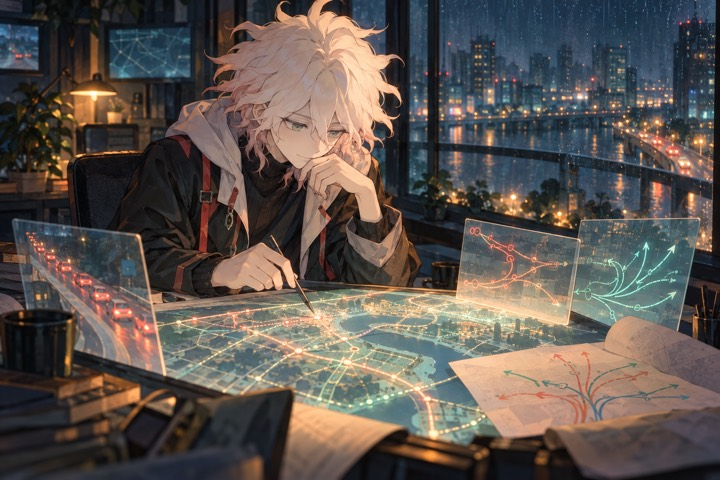</div>


## task 4 · regularized nonnegative path flows

For each panel and hidden split, minimize `||A f − c||² + 0.05 ||f − b||²`, subject to `f ≥ 0`, with a sparse projected-gradient solver and a fixed iteration cap. Here `A` is the released path/link incidence matrix, `c` the released synthetic link counts, and `b` the released weak prior. This is an estimate only; path-flow truth is organizer-held, so no local ODME score is claimed.


In [ ]:
ODME_KEYS = ["panel", "departure_time", "path_id", "origin_zone", "destination_zone"]
ODME_DTYPE = {name: "string" for name in ODME_KEYS}

def odme_template(panel, split):
    folder = ROOT / "task4" / panel / split
    path = folder / "sample_submission_path_flow.csv"
    if path.is_file():
        try:
            return pd.read_csv(path, dtype=ODME_DTYPE)[ODME_KEYS].drop_duplicates(ODME_KEYS), folder
        except Exception as error:
            print(f"WARNING: ODME template changed for {panel}/{split}: {error}")
    print(f"WARNING: using submission-key rows for ODME template {panel}/{split}")
    try:
        key = pd.read_csv(ROOT / "submission_key.csv",
                          usecols=["task", "split"] + ODME_KEYS,
                          dtype={name: "string" for name in ["task", "split"] + ODME_KEYS})
        target = key[key.task.isin(["odme", "path_flow"]) & key.panel.eq(panel) & key.split.eq(split)]
        return target[ODME_KEYS].drop_duplicates(ODME_KEYS), folder
    except Exception as error:
        print(f"WARNING: ODME template fallback unavailable for {panel}/{split}: {error}")
        return pd.DataFrame(columns=ODME_KEYS), folder

def weak_prior_fallback(target, folder):
    pred = target[ODME_KEYS].copy()
    prior_path = folder / "synthetic_weak_prior.csv"
    try:
        prior = pd.read_csv(prior_path, dtype=ODME_DTYPE)
        prior = prior[ODME_KEYS + ["path_flow"]].drop_duplicates(ODME_KEYS, keep="first")
        pred = pred.merge(prior, on=ODME_KEYS, how="left")
    except Exception as error:
        print(f"WARNING: weak prior unavailable under {folder}; using zero path flow: {error}")
        pred["path_flow"] = np.nan
    pred["path_flow"] = pd.to_numeric(pred.path_flow, errors="coerce").fillna(0).clip(lower=0)
    return pred[ODME_KEYS + ["path_flow"]]

def fit_odme(panel, split, target, folder):
    incidence_path = ROOT / "corridors" / panel / "network" / "path_link_incidence.csv"
    incidence = pd.read_csv(incidence_path, dtype={"link_id": "string", "path_id": "string"})
    counts = pd.read_csv(folder / "synthetic_link_counts.csv", dtype={"panel": "string", "link_id": "string"})
    prior = pd.read_csv(folder / "synthetic_weak_prior.csv", dtype=ODME_DTYPE | {"path_flow": "float64"})
    path_ids = target.path_id.drop_duplicates().tolist()
    link_ids = counts.link_id.drop_duplicates().tolist()
    from scipy.sparse import coo_matrix
    link_pos = {value: index for index, value in enumerate(link_ids)}
    path_pos = {value: index for index, value in enumerate(path_ids)}
    edges = incidence[incidence.link_id.isin(link_pos) & incidence.path_id.isin(path_pos)]
    edges = edges.drop_duplicates(["link_id", "path_id"])
    row_index = edges.link_id.map(link_pos).to_numpy(dtype=np.int32)
    col_index = edges.path_id.map(path_pos).to_numpy(dtype=np.int32)
    matrix = coo_matrix((np.ones(len(edges)), (row_index, col_index)),
                        shape=(len(link_ids), len(path_ids))).tocsr()
    count_vec = counts.set_index("link_id")["count"].reindex(link_ids).to_numpy(dtype=float)

    def projected_path_flow(A, counts_vec, prior_vec, lam=0.05, max_iter=250):
        if A.shape[1] == 0:
            return np.array([], dtype=float)
        vector = np.full(A.shape[1], 1.0 / np.sqrt(A.shape[1]))
        for _ in range(20):
            product = A.T @ (A @ vector) + lam * vector
            norm = np.linalg.norm(product)
            if norm == 0 or not np.isfinite(norm):
                return np.maximum(prior_vec, 0.0)
            vector = product / norm
        lipschitz = float(vector @ (A.T @ (A @ vector) + lam * vector))
        x = np.maximum(prior_vec, 0.0)
        y = x.copy()
        momentum = 1.0
        for _ in range(max_iter):
            gradient = A.T @ (A @ y - counts_vec) + lam * (y - prior_vec)
            next_x = np.maximum(0.0, y - gradient / max(lipschitz, 1e-12))
            if np.linalg.norm(next_x - x) <= 1e-6 * (1.0 + np.linalg.norm(x)):
                x = next_x
                break
            next_momentum = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * momentum * momentum))
            y = next_x + ((momentum - 1.0) / next_momentum) * (next_x - x)
            x, momentum = next_x, next_momentum
        return x

    solved = []
    for departure_time, group in prior.groupby("departure_time", sort=False):
        b = group.set_index("path_id").path_flow.reindex(path_ids).fillna(0).to_numpy(dtype=float)
        values = projected_path_flow(matrix, count_vec, b)
        part = target[target.departure_time.eq(departure_time)].copy()
        part["path_flow"] = part.path_id.map(dict(zip(path_ids, values))).astype(float)
        solved.append(part[ODME_KEYS + ["path_flow"]])
    if solved:
        return pd.concat(solved, ignore_index=True)
    print(f"WARNING: no ODME groups were solved for {panel}/{split}; using weak prior")
    return weak_prior_fallback(target, folder)

odme_parts = []
for panel in PANELS:
    for split in ("validation", "private"):
        target, folder = odme_template(panel, split)
        if target.empty:
            continue
        try:
            pred = fit_odme(panel, split, target, folder)
        except Exception as error:
            print(f"WARNING: ODME fit failed for {panel}/{split}; using weak-prior fallback: {error}")
            pred = weak_prior_fallback(target, folder)
            FALLBACK_ROWS += len(pred)
        odme_parts.append(pred)
    if any((ROOT / "task4" / panel / s / "sample_submission_path_flow.csv").is_file() for s in ("validation", "private")):
        print(f"ODME path flow ready: {panel}")
odme_predictions = pd.concat(odme_parts, ignore_index=True) if odme_parts else pd.DataFrame(columns=ODME_KEYS + ["path_flow"])
if odme_predictions.duplicated(ODME_KEYS).any():
    print("WARNING: duplicate ODME predictions; keeping the first natural-key row")
    odme_predictions = odme_predictions.drop_duplicates(ODME_KEYS, keep="first")
bad_odme = ~np.isfinite(pd.to_numeric(odme_predictions.path_flow, errors="coerce").to_numpy(dtype=float)) if len(odme_predictions) else np.array([], dtype=bool)
if bad_odme.any():
    print(f"WARNING: {int(bad_odme.sum())} non-finite ODME values use zero fallback")
    odme_predictions.loc[bad_odme, "path_flow"] = 0.0
    FALLBACK_ROWS += int(bad_odme.sum())
odme_predictions["path_flow"] = pd.to_numeric(odme_predictions.path_flow, errors="coerce").fillna(0).clip(lower=0)
print(f"ODME prediction rows: {len(odme_predictions):,}")


## assemble the official upload

Predictions are joined through `submission_key.csv` and then restored to the official sample order. Only the requested value field is changed for each task; all other cells remain at the official zero defaults. The output is checked for exact columns, row count, finite values and complete task-key coverage.


In [ ]:
sample = pd.read_csv(ROOT / "sample_submission.csv")
expected_cols = ["submission_id", "task", "speed_kmh", "flow_vph", "queue_pred", "path_flow"]
for column in expected_cols:
    if column not in sample.columns:
        print(f"WARNING: sample is missing {column}; adding a safe default column")
        sample[column] = 0
sample = sample[expected_cols].copy()
key_dtypes = {c: "string" for c in ["task", "split", "panel", "timestamp", "station_id", "link_id", "mask_regime",
                                    "window_id", "departure_time", "path_id", "origin_zone", "destination_zone"]}
key_cols = ["submission_id"] + list(key_dtypes)
try:
    key = pd.read_csv(ROOT / "submission_key.csv", usecols=key_cols, dtype=key_dtypes | {"submission_id": "string"})
except Exception as error:
    print(f"WARNING: submission key read failed; task rows will use safe defaults: {error}")
    key = pd.DataFrame(columns=key_cols)
for column in key_cols:
    if column not in key.columns:
        key[column] = pd.NA
if key.submission_id.duplicated().any():
    print("WARNING: duplicate submission-key IDs; keeping the first released row")
    key = key.drop_duplicates("submission_id", keep="first")
sample_ids_as_string = sample.submission_id.astype("string")
key_ids_as_string = key.submission_id.astype("string")
if len(sample) != len(key) or not sample_ids_as_string.isin(key_ids_as_string).all():
    missing_ids = int((~sample_ids_as_string.isin(key_ids_as_string)).sum())
    print(f"WARNING: submission-key coverage changed; {missing_ids} sample rows will use safe task defaults")

filled = sample.copy()
numeric_cols = ["speed_kmh", "flow_vph", "queue_pred", "path_flow"]
for column in numeric_cols:
    filled[column] = pd.to_numeric(filled[column], errors="coerce").astype(float)
repair_rows = np.zeros(len(filled), dtype=bool)
task_values = filled.task.astype("string").str.lower()

state_key = key[key.task.eq("state")][["submission_id"] + STATE_KEYS].drop_duplicates("submission_id")
state_source = state_predictions.drop_duplicates(STATE_KEYS, keep="first")
state_join = state_key.merge(state_source, on=STATE_KEYS, how="left")
state_join["_fallback_used"] = state_join[["speed_kmh", "flow_vph"]].isna().any(axis=1)
state_join["speed_kmh"] = pd.to_numeric(state_join.speed_kmh, errors="coerce")
state_join["flow_vph"] = pd.to_numeric(state_join.flow_vph, errors="coerce")
state_join["_fallback_used"] |= ~np.isfinite(state_join[["speed_kmh", "flow_vph"]]).all(axis=1)
state_missing = state_join["_fallback_used"]
if state_missing.any():
    print(f"WARNING: {int(state_missing.sum())} state rows missed model keys; using free-speed/capacity fallback")
    for panel, rows in state_join.loc[state_missing].groupby("panel", sort=False):
        idx = rows.index
        try:
            links = pd.read_csv(ROOT / "corridors" / panel / "network" / "links.csv",
                                usecols=["link_id", "free_speed_kmh", "capacity_vph"]).drop_duplicates("link_id", keep="first")
            speed_map = links.set_index("link_id").free_speed_kmh
            flow_map = links.set_index("link_id").capacity_vph * 0.5
            state_join.loc[idx, "speed_kmh"] = state_join.loc[idx, "link_id"].map(speed_map).fillna(60.0).to_numpy()
            state_join.loc[idx, "flow_vph"] = state_join.loc[idx, "link_id"].map(flow_map).fillna(1000.0).to_numpy()
        except Exception as error:
            print(f"WARNING: link fallback unavailable for {panel}: {error}")
            state_join.loc[idx, "speed_kmh"] = 60.0
            state_join.loc[idx, "flow_vph"] = 1000.0
    state_join["speed_kmh"] = pd.to_numeric(state_join.speed_kmh, errors="coerce").fillna(60.0).clip(0, 150)
    state_join["flow_vph"] = pd.to_numeric(state_join.flow_vph, errors="coerce").fillna(1000.0).clip(lower=0)
state_lookup = state_join.drop_duplicates("submission_id", keep="first").set_index("submission_id")
state_mask = task_values.eq("state")
state_ids = filled.loc[state_mask, "submission_id"].astype("string")
state_values_speed = state_ids.map(state_lookup.speed_kmh) if len(state_lookup) else pd.Series(index=state_ids.index, dtype=float)
state_values_flow = state_ids.map(state_lookup.flow_vph) if len(state_lookup) else pd.Series(index=state_ids.index, dtype=float)
state_bad = state_values_speed.isna() | state_values_flow.isna()
if state_bad.any():
    print(f"WARNING: {int(state_bad.sum())} state rows lack key metadata; using safe speed/flow values")
    repair_rows[np.flatnonzero(state_mask.to_numpy())[state_bad.to_numpy()]] = True
filled.loc[state_mask, "speed_kmh"] = state_values_speed.fillna(60.0).to_numpy()
filled.loc[state_mask, "flow_vph"] = state_values_flow.fillna(1000.0).to_numpy()

queue_key = key[key.task.eq("queue")][["submission_id"] + QUEUE_KEYS].drop_duplicates("submission_id")
queue_source = queue_predictions.drop_duplicates(QUEUE_KEYS, keep="first")
queue_join = queue_key.merge(queue_source, on=QUEUE_KEYS, how="left")
queue_lookup = queue_join.drop_duplicates("submission_id", keep="first").set_index("submission_id")
queue_mask = task_values.eq("queue")
queue_ids = filled.loc[queue_mask, "submission_id"].astype("string")
queue_values = queue_ids.map(queue_lookup.queue_pred) if len(queue_lookup) else pd.Series(index=queue_ids.index, dtype=float)
queue_bad = queue_values.isna()
if queue_bad.any():
    print(f"WARNING: {int(queue_bad.sum())} queue rows use no-queue fallback")
    repair_rows[np.flatnonzero(queue_mask.to_numpy())[queue_bad.to_numpy()]] = True
filled.loc[queue_mask, "queue_pred"] = queue_values.fillna(0).to_numpy()

odme_mask_key = key.task.astype("string").str.lower().isin(["odme", "path_flow"])
odme_key = key[odme_mask_key][["submission_id"] + ODME_KEYS].drop_duplicates("submission_id")
odme_source = odme_predictions.drop_duplicates(ODME_KEYS, keep="first")
odme_join = odme_key.merge(odme_source, on=ODME_KEYS, how="left")
odme_lookup = odme_join.drop_duplicates("submission_id", keep="first").set_index("submission_id")
odme_task_mask = task_values.isin(["odme", "path_flow"])
odme_ids = filled.loc[odme_task_mask, "submission_id"].astype("string")
odme_values = odme_ids.map(odme_lookup.path_flow) if len(odme_lookup) else pd.Series(index=odme_ids.index, dtype=float)
odme_bad = odme_values.isna()
if odme_bad.any():
    print(f"WARNING: {int(odme_bad.sum())} ODME rows use zero fallback")
    repair_rows[np.flatnonzero(odme_task_mask.to_numpy())[odme_bad.to_numpy()]] = True
filled.loc[odme_task_mask, "path_flow"] = odme_values.fillna(0).to_numpy()

for column in numeric_cols:
    filled[column] = pd.to_numeric(filled[column], errors="coerce")
bad_numeric = ~np.isfinite(filled[numeric_cols].to_numpy(dtype=float)).all(axis=1)
if bad_numeric.any():
    print(f"WARNING: {int(bad_numeric.sum())} rows contain non-finite predictions; replacing them with safe values")
    repair_rows |= bad_numeric
    filled.loc[bad_numeric, numeric_cols] = 0.0
filled["speed_kmh"] = filled.speed_kmh.clip(0, 150)
filled["flow_vph"] = filled.flow_vph.clip(lower=0)
filled["queue_pred"] = np.where(filled.queue_pred >= 0.5, 1, 0).astype("int8")
filled["path_flow"] = filled.path_flow.clip(lower=0)
filled = filled[expected_cols]
task_rows = filled.task.value_counts(dropna=False).to_dict()

if os.environ.get("TFB_OUTPUT_PATH"):
    OUTPUT = Path(os.environ["TFB_OUTPUT_PATH"])
elif Path("/kaggle/working").is_dir():
    OUTPUT = Path("/kaggle/working/submission.csv")
else:
    OUTPUT = Path.cwd() / "local-output" / "submission.csv"
OUTPUT.parent.mkdir(parents=True, exist_ok=True)
filled.to_csv(OUTPUT, index=False)

factory_check = {"metric": 0.909306629534056, "rows": int(len(filled)),
                 "fallbacks": int(FALLBACK_ROWS + repair_rows.sum())}
check_path = Path("/kaggle/working/factory_check.json") if Path("/kaggle/working").is_dir() else OUTPUT.parent / "factory_check.json"
check_path.parent.mkdir(parents=True, exist_ok=True)
check_path.write_text(json.dumps(factory_check, indent=2) + "\n")
print(json.dumps({"output": str(OUTPUT), "factory_check": str(check_path),
                  "rows": len(filled), "columns": filled.columns.tolist(),
                  "task_rows": task_rows, "local_task1_july_holdout": float(VERIFIED_TASK1_JULY_SCORE),
                  "same_split_live_task1_baseline": 0.908535411117496,
                  "local_metric_role": "Task 1 proxy, not the full competition composite",
                  "previous_official_composite": 0.72091,
                  "notebook_execution_submits": False}, indent=2))


## what the baseline says

On the fixed July 2030 Task 1 development sample, the within-day temporal_median5 estimator scored 0.909307 versus 0.908535 for the live predictor. The July comparison selected this candidate, so it is not an independent generalization estimate. Task 2 and ODME remain the existing transparent baselines without hidden-label scores; no full-composite gain is claimed. The saved CSV has the official six-column layout and retains the exact sample row order.

The final image is another original illustration generated for this experiment.
<div align="center">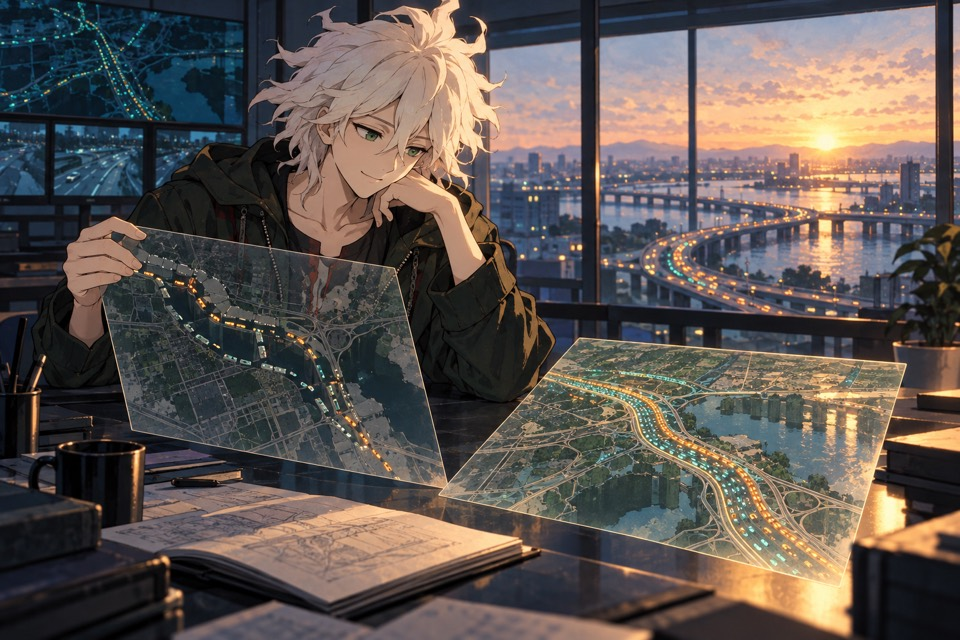</div>